# Card A — Price Paid Data

**Best archetype:** Predictor / Dashboard. Every property sale in England & Wales (1995–now).

**Your task:** pick ONE — a price **predictor** or a price **dashboard** — for a real citizen (e.g. a first-time buyer choosing a street to live on).

> Contains HM Land Registry data © Crown copyright and database right 2021. Licensed under the Open Government Licence v3.0.

Columns & quirks: `../02-data-pack/A-house-prices/data_dictionary.md`

In [1]:
import pandas as pd
import plotly.express as px

DATA = "../02-data-pack/A-house-prices/price_paid_subset.csv"
COLS = ["transaction_id", "price", "date", "postcode", "type", "new_or_existing",
        "duration", "paon", "saon", "street", "locality", "town", "district",
        "county", "ppd_category", "record_status"]
df = pd.read_csv(DATA, header=None, names=COLS)
df["price"] = pd.to_numeric(df["price"])
df["date"] = pd.to_datetime(df["date"])
df = df[df["record_status"] == "A"]          # A = Added (drop C = Cancelled)
df = df.dropna(subset=["price", "date"])
TYPE = {"T": "Terraced", "D": "Detached", "S": "Semi-detached", "F": "Flat/Maisonette", "O": "Other"}
df["type"] = df["type"].map(TYPE).fillna(df["type"])
df

,transaction_id,price,date,postcode,type,new_or_existing,duration,paon,saon,street,locality,town,district,county,ppd_category,record_status
0,{559C5AD5-28EE-AFE3-E063-4804A8C004A4},285000,2026-05-29,HU18 1TS,Detached,N,F,38,NaN,TANSLEY LANE,NaN,HORNSEA,EAST RIDING OF YORKSHIRE,EAST RIDING OF YORKSHIRE,A,A
1,{559C5AD5-28EF-AFE3-E063-4804A8C004A4},300000,2026-01-23,DN37 0HU,Semi-detached,N,F,ST DAVIDS,NaN,CHEAPSIDE,WALTHAM,GRIMSBY,NORTH EAST LINCOLNSHIRE,NORTH EAST LINCOLNSHIRE,A,A
2,{559C5AD5-28F0-AFE3-E063-4804A8C004A4},350000,2026-06-05,DN9 1HD,Detached,N,F,3,NaN,ALBION HILL,EPWORTH,DONCASTER,NORTH LINCOLNSHIRE,NORTH LINCOLNSHIRE,A,A
3,{559C5AD5-28F1-AFE3-E063-4804A8C004A4},162500,2026-05-15,DN36 4YA,Semi-detached,N,F,29,NaN,FARMHOUSE MEWS,NEW WALTHAM,GRIMSBY,NORTH EAST LINCOLNSHIRE,NORTH EAST LINCOLNSHIRE,A,A
4,{559C5AD5-28F2-AFE3-E063-4804A8C004A4},269500,2026-05-22,HU13 0QA,Semi-detached,N,F,5,NaN,MAY GROVE,NaN,HESSLE,EAST RIDING OF YORKSHIRE,EAST RIDING OF YORKSHIRE,A,A
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,{559C5AD5-AB15-AFE3-E063-4804A8C004A4},153000,2026-01-05,CF35 6YS,Terraced,N,F,12,NaN,BRO DEG,PENCOED,BRIDGEND,BRIDGEND,BRIDGEND,A,A
29996,{559C5AD5-AB16-AFE3-E063-4804A8C004A4},190000,2026-05-08,CF63 2JF,Terraced,N,F,38,NaN,QUARELLA STREET,NaN,BARRY,THE VALE OF GLAMORGAN,THE VALE OF GLAMORGAN,A,A
29997,{559C5AD5-AB17-AFE3-E063-4804A8C004A4},391000,2026-04-24,SA2 7EX,Semi-detached,N,F,644,NaN,GOWER ROAD,UPPER KILLAY,SWANSEA,SWANSEA,SWANSEA,A,A
29998,{559C5AD5-AB18-AFE3-E063-4804A8C004A4},495000,2026-05-18,CF83 1TA,Detached,N,F,29,NaN,HEOL YR YSBYTY,NaN,CAERPHILLY,CAERPHILLY,CAERPHILLY,A,A


## 1. Sanity check (data dive)

Answer these before you build:
- How many rows? What is the date range?
- Any nulls in `price`, `date`, `type`, `town`?
- What is the median price? How does it differ by `type`?

In [2]:
print("rows:", len(df))
print("date range:", df["date"].min(), "->", df["date"].max())
print("nulls:\n", df[["price", "date", "type", "town"]].isna().sum())
print("median price:", df["price"].median())
df["type"].value_counts()

rows: 30000
date range: 2026-01-02 00:00:00 -> 2026-07-31 00:00:00
nulls:
 price    0
date     0
type     0
town     0
dtype: int64
median price: 280000.0


type
Terraced           9097
Semi-detached      8713
Detached           6710
Flat/Maisonette    4790
Other               690
Name: count, dtype: int64

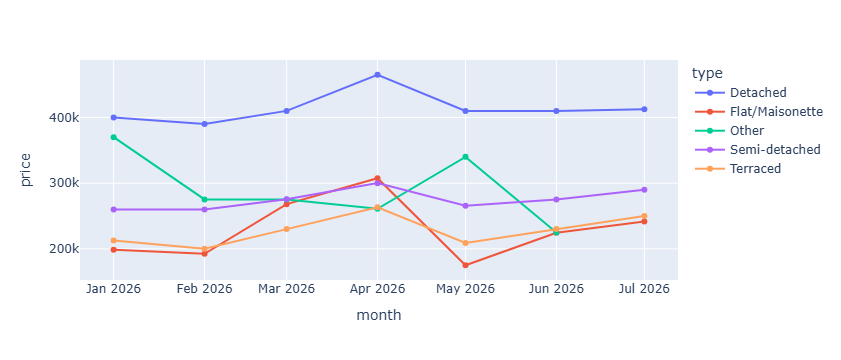

In [3]:
# Example chart: median price over time by property type
df["month"] = df["date"].dt.to_period("M").astype(str)
med = df.groupby(["month", "type"])["price"].median().reset_index()
px.line(med, x="month", y="price", color="type", markers=True)

## 2. Your turn — pick ONE and build it

- **Predictor:** estimate `price` from `type` + `town` + `year`. Start with a **baseline** (median by group), then try a linear model.
- **Dashboard:** a 2–3 chart view a citizen would actually use (trend + by type + by area).

Use Feniks to generate code — but **verify every number against the data** before you show it.

In [ ]:
# Your build here

In [ ]:
# Your build here

In [ ]:
# Your build here